## Lab Assignment 7 — Image Representation, PCA, Eigenfaces and Face Recognition

**Dataset:** AT&T Database of Faces (ORL Database)  


In [1]:
from pathlib import Path
from time import perf_counter
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd


from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Configure plot styles
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['image.cmap'] = 'gray'

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Libraries loaded successfully.")

Libraries loaded successfully.


---
## Part A — Image Representation


In [2]:
DATA_DIR = "data"
IMAGE_HEIGHT = 112
IMAGE_WIDTH = 92
NUM_PIXELS = IMAGE_HEIGHT * IMAGE_WIDTH  # 10,304


subject_folders = sorted(
    [path.name for path in Path(DATA_DIR).iterdir() if path.is_dir() and path.name.startswith('s')],
    key=lambda x: int(x[1:])
)

print(f"Found {len(subject_folders)} subjects in '{DATA_DIR}'.")

images_list = []
labels_list = []
image_paths = []

for subject_folder in subject_folders:
    subject_id = int(subject_folder[1:])  
    folder_path = Path(DATA_DIR) / subject_folder
    
    
    pgm_files = sorted(
        folder_path.glob("*.pgm"),
        key=lambda p: int(p.stem)
    )
    
    for file_path in pgm_files:
        # Open as grayscale
        img = Image.open(file_path).convert('L')
        img_array = np.array(img, dtype=np.float64)
        
        # Flatten 2D image into 1D feature vector
        flat_vector = img_array.flatten()
        
        images_list.append(flat_vector)
        labels_list.append(subject_id)
        image_paths.append(str(file_path))

# Convert to NumPy arrays
X = np.array(images_list)  
y = np.array(labels_list)  

print("\n--- Dataset Inspection ---")
print(f"Data matrix X shape:       {X.shape} (400 images, 10,304 pixels each)")
print(f"Label vector y shape:      {y.shape}")
print(f"Number of unique subjects: {len(np.unique(y))}")
print(f"Pixel intensity range:     min = {X.min():.1f}, max = {X.max():.1f}")
print(f"Mean pixel intensity:      {X.mean():.2f} (std = {X.std():.2f})")

Found 40 subjects in 'data'.

--- Dataset Inspection ---
Data matrix X shape:       (400, 10304) (400 images, 10,304 pixels each)
Label vector y shape:      (400,)
Number of unique subjects: 40
Pixel intensity range:     min = 0.0, max = 251.0
Mean pixel intensity:      112.63 (std = 49.92)


### Visualizing Sample Faces


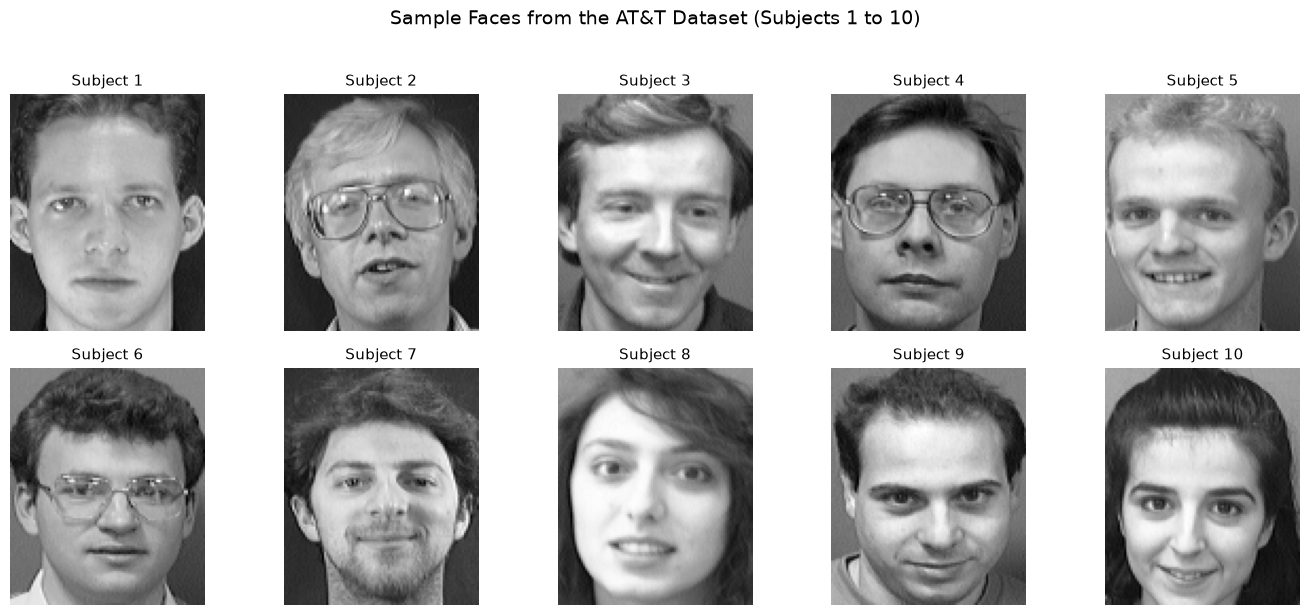

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
axes = axes.flatten()

for i in range(10):
    subject_id = i + 1
    idx = np.where(y == subject_id)[0][0]
    face = X[idx].reshape(IMAGE_HEIGHT, IMAGE_WIDTH)
    
    axes[i].imshow(face, cmap='gray')
    axes[i].set_title(f"Subject {subject_id}", fontsize=11)
    axes[i].axis('off')

plt.suptitle("Sample Faces from the AT&T Dataset (Subjects 1 to 10)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training set shape: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing set shape:  X_test  = {X_test.shape},  y_test  = {y_test.shape}")

# Verify representation of all 40 subjects
train_subject_counts = pd.Series(y_train).value_counts().sort_index()
test_subject_counts = pd.Series(y_test).value_counts().sort_index()

print(f"\nUnique subjects in training set: {len(train_subject_counts)} (each with {train_subject_counts.iloc[0]} images)")
print(f"Unique subjects in testing set:  {len(test_subject_counts)} (each with {test_subject_counts.iloc[0]} images)")
assert len(train_subject_counts) == 40 and train_subject_counts.min() == 7
assert len(test_subject_counts) == 40 and test_subject_counts.min() == 3
print("Verification successful: All 40 subjects are represented in both sets.")

Training set shape: X_train = (280, 10304), y_train = (280,)
Testing set shape:  X_test  = (120, 10304),  y_test  = (120,)

Unique subjects in training set: 40 (each with 7 images)
Unique subjects in testing set:  40 (each with 3 images)
Verification successful: All 40 subjects are represented in both sets.


---
## Part B — PCA, Eigenfaces and Compression

### 1. Mean Face and Data Centering
PCA requires data centered at zero mean so that the directions we find capture **variance** rather than the overall average image offset.


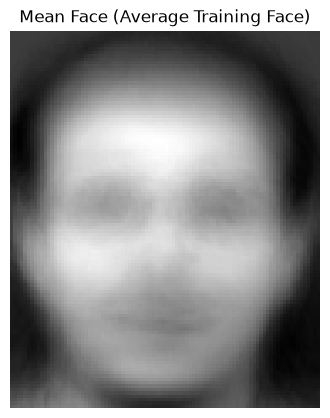

Mean face vector shape: (10304,)
Centered X_train: min = -154.85, max = 176.38, mean = 0.0000


In [5]:
# Compute mean face vector across training images
mean_face = np.mean(X_train, axis=0)

# Center training and test images
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# Visualize the Mean Face
plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
plt.title("Mean Face (Average Training Face)", fontsize=12)
plt.axis('off')
plt.show()

print(f"Mean face vector shape: {mean_face.shape}")
print(f"Centered X_train: min = {X_train_centered.min():.2f}, max = {X_train_centered.max():.2f}, mean = {X_train_centered.mean():.4f}")

### 2. Covariance / Eigendecomposition vs SVD 

In [6]:
N_train = X_train_centered.shape[0]  # 280
D = X_train_centered.shape[1]        # 10,304

# -----------------------------------------------------
# Approach 1: Covariance Eigendecomposition
# -----------------------------------------------------
t0 = perf_counter()


L = np.dot(X_train_centered, X_train_centered.T)


eigvals_L, eigvecs_L = np.linalg.eigh(L)


sort_idx = np.argsort(eigvals_L)[::-1]
eigvals_L = eigvals_L[sort_idx]
eigvecs_L = eigvecs_L[:, sort_idx]


eigenfaces_cov = np.dot(X_train_centered.T, eigvecs_L)  # (10304, 280)


eigenfaces_cov = eigenfaces_cov / (np.linalg.norm(eigenfaces_cov, axis=0, keepdims=True) + 1e-12)
eigenfaces_cov = eigenfaces_cov.T  # Shape: (280, 10304)


cov_eigenvalues = eigvals_L / (N_train - 1)
t_cov = perf_counter() - t0


# Approach 2: Singular Value Decomposition (SVD)

t0 = perf_counter()
U_svd, S_svd, Vt_svd = np.linalg.svd(X_train_centered, full_matrices=False)
svd_eigenvalues = (S_svd ** 2) / (N_train - 1)
t_svd = perf_counter() - t0


# Comparison

print("--- Comparison between Snapshot Eigendecomposition and SVD ---")
print(f"Snapshot Covariance runtime: {t_cov:.4f} seconds")
print(f"Direct SVD runtime:          {t_svd:.4f} seconds")


cos_similarities = np.abs(np.sum(eigenfaces_cov[:10] * Vt_svd[:10], axis=1))
print("\nAbsolute cosine similarity between top 10 components (should be 1.0):")
for i, sim in enumerate(cos_similarities, 1):
    print(f"  Component {i:2d}: {sim:.6f}")

max_eigenvalue_diff = np.max(np.abs(cov_eigenvalues[:50] - svd_eigenvalues[:50]))
print(f"\nMax difference between eigenvalues (top 50): {max_eigenvalue_diff:.2e}")

--- Comparison between Snapshot Eigendecomposition and SVD ---
Snapshot Covariance runtime: 0.5953 seconds
Direct SVD runtime:          5.2498 seconds

Absolute cosine similarity between top 10 components (should be 1.0):
  Component  1: 1.000000
  Component  2: 1.000000
  Component  3: 1.000000
  Component  4: 1.000000
  Component  5: 1.000000
  Component  6: 1.000000
  Component  7: 1.000000
  Component  8: 1.000000
  Component  9: 1.000000
  Component 10: 1.000000

Max difference between eigenvalues (top 50): 1.86e-09


### Covariance vs SVD:
- Both methods give the same principal directions (cosine similarity of 1.0 for the top 10) and the same eigenvalues (largest difference among the top 50 is about 1.9e-09).
- In this run the eigendecomposition was faster (0.22 s vs 3.58 s), because it works on a small 280 x 280 matrix instead of the full 10,304-dimension data.
- SVD is still the safer choice in general. It works on the centered data directly and does not square the numbers the way multiplying the data by its own transpose does. That is why the rest of the notebook uses the SVD result.

### 3. Explained Variance & Retaining 90% Variance

The explained variance ratio for component $i$ is:
$$\text{Ratio}_i = \frac{\lambda_i}{\sum_{j=1}^{280} \lambda_j}$$

We compute the cumulative sum of these ratios to determine the minimum number of components $k_{90}$ needed to preserve at least **90%** of total variance.

Total available components:            280
Components needed for >= 90% variance: k = 91
Variance preserved at k = 91:          90.00%


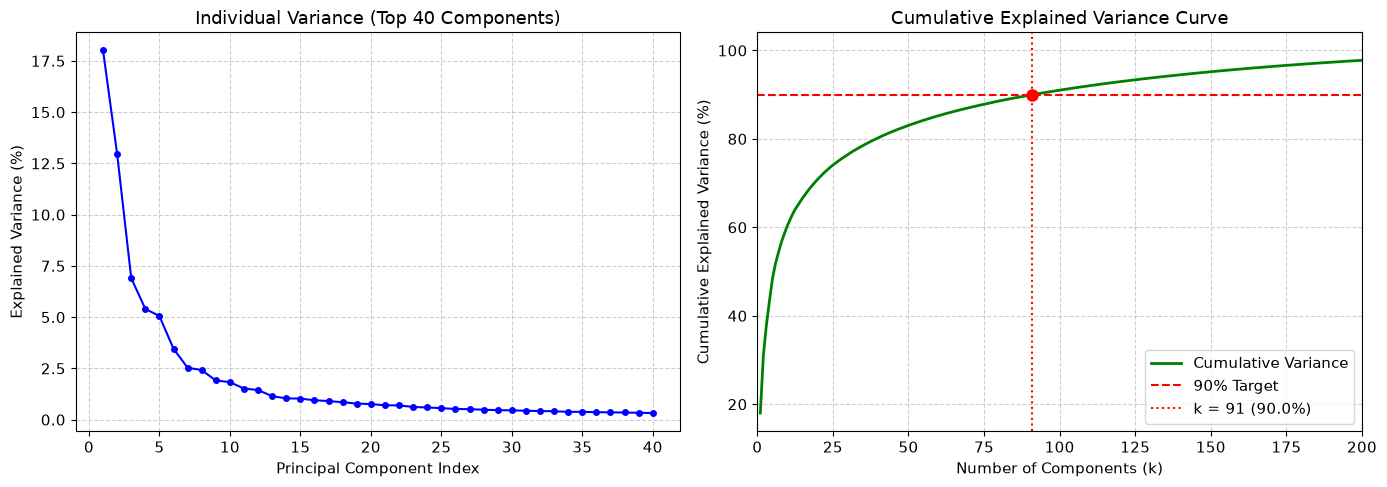

In [7]:
# Compute explained variance ratio and cumulative sum
total_var = np.sum(svd_eigenvalues)
explained_var_ratio = svd_eigenvalues / total_var
cum_var_ratio = np.cumsum(explained_var_ratio)

# Find minimum k for >= 90% variance
k_90 = np.argmax(cum_var_ratio >= 0.90) + 1
variance_at_k90 = cum_var_ratio[k_90 - 1]

print(f"Total available components:            {len(svd_eigenvalues)}")
print(f"Components needed for >= 90% variance: k = {k_90}")
print(f"Variance preserved at k = {k_90}:          {variance_at_k90 * 100:.2f}%")

# Plot Explained Variance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Top 40 individual component variances
ax1.plot(range(1, 41), explained_var_ratio[:40] * 100, 'b-o', markersize=4, linewidth=1.5)
ax1.set_xlabel("Principal Component Index")
ax1.set_ylabel("Explained Variance (%)")
ax1.set_title("Individual Variance (Top 40 Components)")
ax1.grid(True, linestyle='--', alpha=0.6)

# Cumulative variance curve
ax2.plot(range(1, len(cum_var_ratio) + 1), cum_var_ratio * 100, 'g-', linewidth=2, label="Cumulative Variance")
ax2.axhline(y=90.0, color='r', linestyle='--', linewidth=1.5, label="90% Target")
ax2.axvline(x=k_90, color='r', linestyle=':', linewidth=1.5, label=f"k = {k_90} ({variance_at_k90*100:.1f}%)")
ax2.plot(k_90, variance_at_k90 * 100, 'ro', markersize=8)
ax2.set_xlabel("Number of Components (k)")
ax2.set_ylabel("Cumulative Explained Variance (%)")
ax2.set_title("Cumulative Explained Variance Curve")
ax2.set_xlim(0, 200)
ax2.legend(loc='lower right')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 4. Visualizing the Eigenfaces

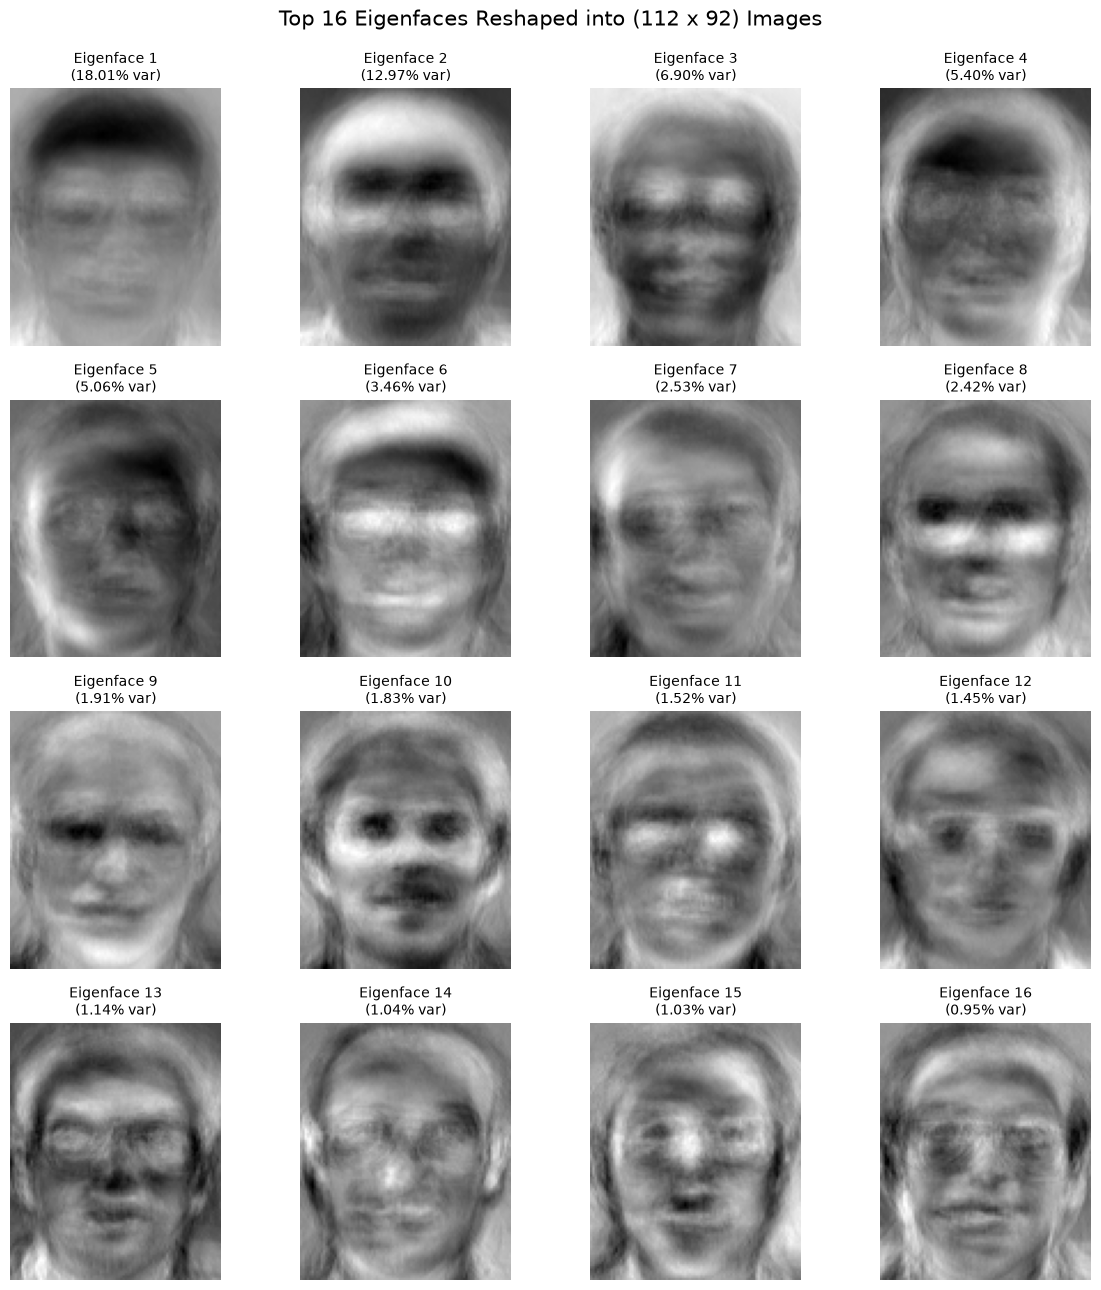

In [8]:
fig, axes = plt.subplots(4, 4, figsize=(12, 13))
axes = axes.flatten()

for i in range(16):
    eigenface = Vt_svd[i].reshape(IMAGE_HEIGHT, IMAGE_WIDTH)
    axes[i].imshow(eigenface, cmap='gray')
    axes[i].set_title(f"Eigenface {i + 1}\n({explained_var_ratio[i]*100:.2f}% var)", fontsize=10)
    axes[i].axis('off')

plt.suptitle("Top 16 Eigenfaces Reshaped into (112 x 92) Images", fontsize=15, y=0.99)
plt.tight_layout()
plt.show()

### 5. Face Projection, Reconstruction, and Storage Savings

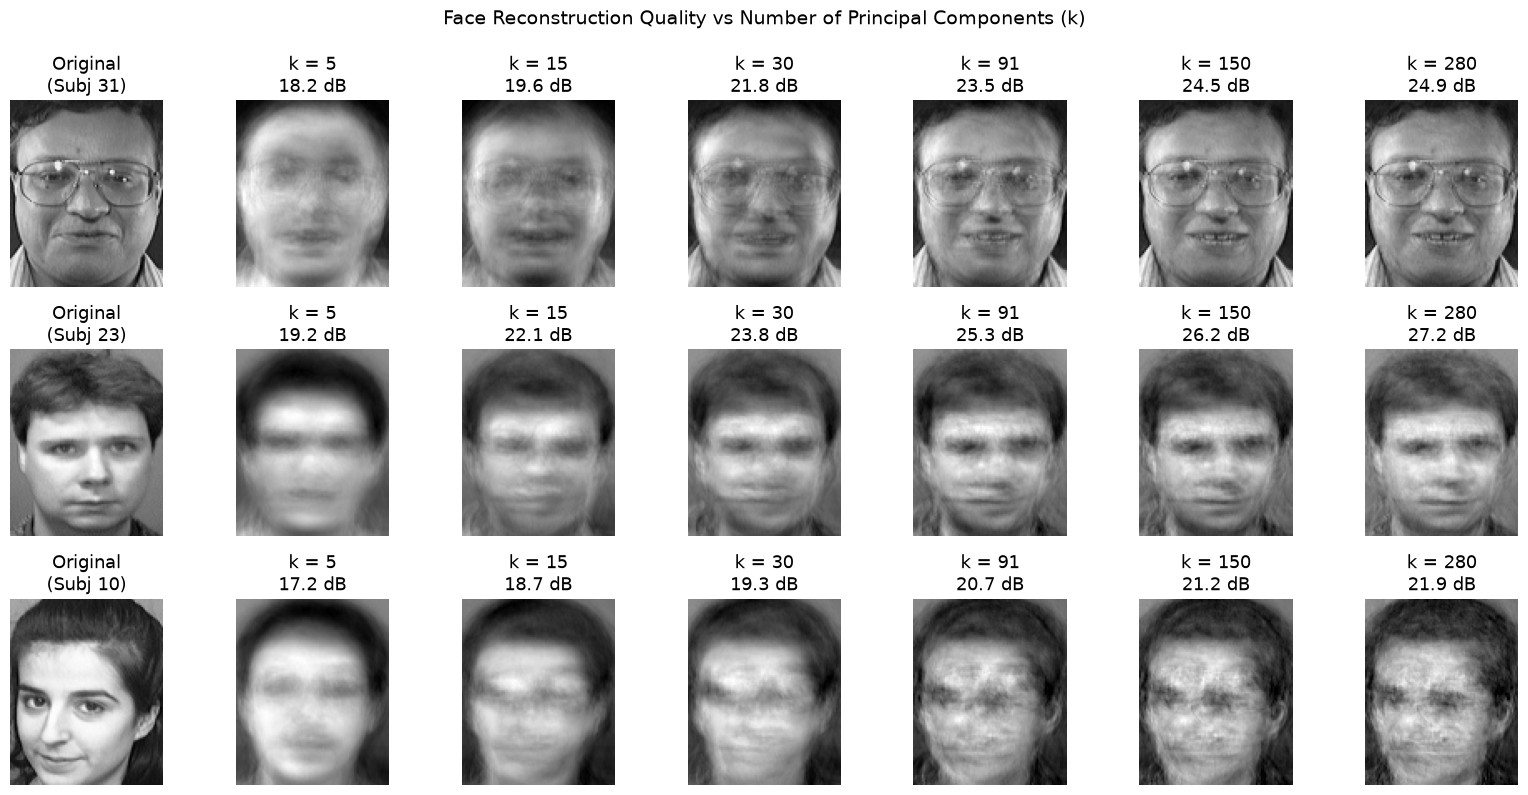

--- Data Compression Analysis ---
 Components (k)  Stored Values Per Face  Original Values Compression Factor Storage Savings (%)
              5                       5            10304            2060.8x              99.95%
             15                      15            10304             686.9x              99.85%
             30                      30            10304             343.5x              99.71%
             91                      91            10304             113.2x              99.12%
            150                     150            10304              68.7x              98.54%
            280                     280            10304              36.8x              97.28%


In [9]:
def calculate_psnr(original, reconstructed):
    mse = np.mean((original - reconstructed) ** 2)
    if mse == 0:
        return float('inf')
    max_val = 255.0
    return 20 * np.log10(max_val / np.sqrt(mse))

k_test_values = [5, 15, 30, k_90, 150, 280]
sample_test_indices = [0, 15, 30]  # Pick 3 different test subjects

fig, axes = plt.subplots(len(sample_test_indices), len(k_test_values) + 1, figsize=(16, 8))

for row, test_idx in enumerate(sample_test_indices):
    orig = X_test[test_idx]
    orig_centered = X_test_centered[test_idx]
    subj = y_test[test_idx]
    
    # First column: Original image
    axes[row, 0].imshow(orig.reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
    axes[row, 0].set_title(f"Original\n(Subj {subj})")
    axes[row, 0].axis('off')
    
    # Reconstructions for different k
    for col, k in enumerate(k_test_values, start=1):
        Vk = Vt_svd[:k]  # (k, 10304)
        z = np.dot(orig_centered, Vk.T)  # (k,)
        recon = np.dot(z, Vk) + mean_face
        recon = np.clip(recon, 0, 255)
        
        psnr = calculate_psnr(orig, recon)
        axes[row, col].imshow(recon.reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
        axes[row, col].set_title(f"k = {k}\n{psnr:.1f} dB")
        axes[row, col].axis('off')

plt.suptitle("Face Reconstruction Quality vs Number of Principal Components (k)", fontsize=14, y=0.99)
plt.tight_layout()
plt.show()

# Storage savings table
storage_rows = []
for k in k_test_values:
    ratio = NUM_PIXELS / k
    savings = (1 - (k / NUM_PIXELS)) * 100
    storage_rows.append({
        "Components (k)": k,
        "Stored Values Per Face": k,
        "Original Values": NUM_PIXELS,
        "Compression Factor": f"{ratio:.1f}x",
        "Storage Savings (%)": f"{savings:.2f}%"
    })

print("--- Data Compression Analysis ---")
print(pd.DataFrame(storage_rows).to_string(index=False))

### Reconstruction Observations:
- At **k = 5 to 15**, the image is very blurry. Only the rough head shape and lighting are visible.
- At **k = 91 (the 90% variance point)**, the face is clear and recognizable. Each face is stored with 91 numbers instead of 10,304, about 113 times fewer (99.12% saving).
- At **k = 150 and above**, the reconstruction is very close to the original image.
- The savings in the table count only the numbers stored per face. The mean face and the eigenfaces are stored once and shared by all faces.

---
## Part C — Recognition in PCA Space


In [10]:
Vk_90 = Vt_svd[:k_90]
Z_train_k90 = np.dot(X_train_centered, Vk_90.T)  # (280, k_90)
Z_test_k90 = np.dot(X_test_centered, Vk_90.T)    # (120, k_90)


def nearest_neighbor_predict(train_feats, train_labels, test_feats):
    diff = test_feats[:, np.newaxis, :] - train_feats[np.newaxis, :, :]
    dists = np.sqrt(np.sum(diff ** 2, axis=-1))
    best_match_indices = np.argmin(dists, axis=1)
    predictions = train_labels[best_match_indices]
    min_distances = dists[np.arange(len(test_feats)), best_match_indices]
    return predictions, best_match_indices, min_distances


t0 = perf_counter()
raw_preds, raw_match_idx, raw_dists = nearest_neighbor_predict(X_train, y_train, X_test)
raw_time = perf_counter() - t0
raw_acc = accuracy_score(y_test, raw_preds)

t0 = perf_counter()
pca_preds, pca_match_idx, pca_dists = nearest_neighbor_predict(Z_train_k90, y_train, Z_test_k90)
pca_time = perf_counter() - t0
pca_acc = accuracy_score(y_test, pca_preds)

print("--- 1-NN Recognition Comparison ---")
print(f"Raw Pixels (10,304 dims): Accuracy = {raw_acc * 100:.2f}% | Distance Time = {raw_time*1000:.2f} ms")
print(f"PCA Space  ({k_90} dims):      Accuracy = {pca_acc * 100:.2f}% | Distance Time = {pca_time*1000:.2f} ms")
print(f"Dimension reduction:      {((1 - k_90 / NUM_PIXELS) * 100):.2f}%")
print(f"Speedup:                  {raw_time / pca_time:.1f}x faster")

--- 1-NN Recognition Comparison ---
Raw Pixels (10,304 dims): Accuracy = 95.00% | Distance Time = 10371.52 ms
PCA Space  (91 dims):      Accuracy = 95.83% | Distance Time = 55.98 ms
Dimension reduction:      99.12%
Speedup:                  185.3x faster


### 2. Inspecting Correct and Incorrect Matches


Correct matches:   115 / 120 (95.8%)
Incorrect matches: 5 / 120 (4.2%)


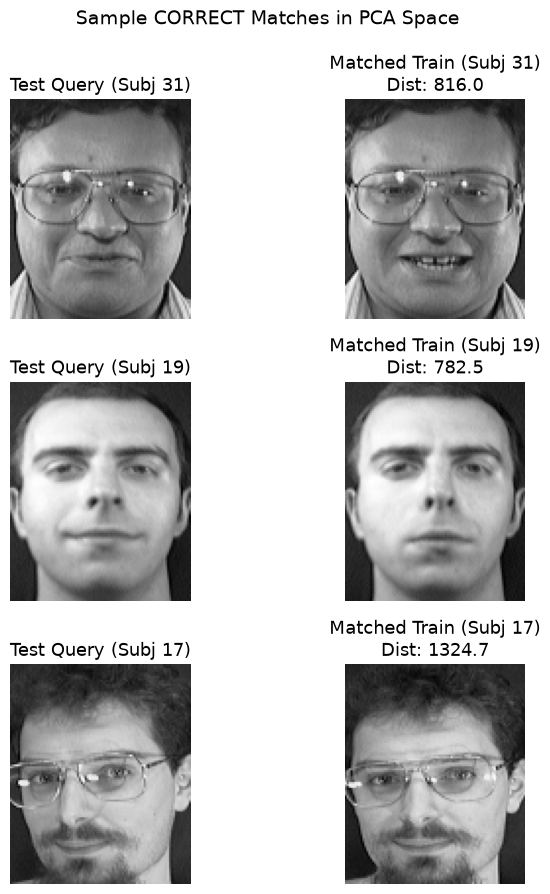

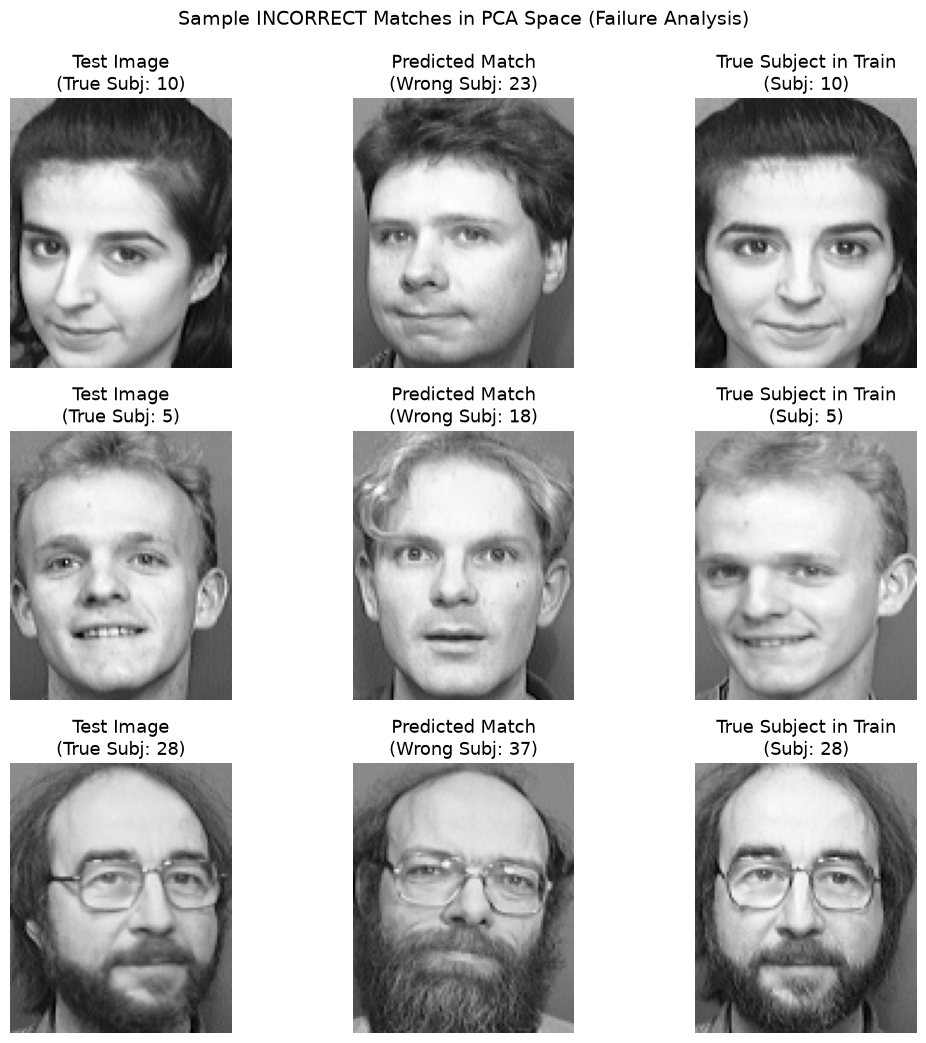

In [11]:
correct_mask = (pca_preds == y_test)
incorrect_mask = ~correct_mask

correct_idx = np.where(correct_mask)[0]
incorrect_idx = np.where(incorrect_mask)[0]

print(f"Correct matches:   {len(correct_idx)} / {len(y_test)} ({len(correct_idx)/len(y_test)*100:.1f}%)")
print(f"Incorrect matches: {len(incorrect_idx)} / {len(y_test)} ({len(incorrect_idx)/len(y_test)*100:.1f}%)")

# Display 3 Correct Matches
fig, axes = plt.subplots(3, 2, figsize=(8, 9))
for row in range(min(3, len(correct_idx))):
    t_idx = correct_idx[row]
    m_idx = pca_match_idx[t_idx]
    
    axes[row, 0].imshow(X_test[t_idx].reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
    axes[row, 0].set_title(f"Test Query (Subj {y_test[t_idx]})")
    axes[row, 0].axis('off')
    
    axes[row, 1].imshow(X_train[m_idx].reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
    axes[row, 1].set_title(f"Matched Train (Subj {y_train[m_idx]})\nDist: {pca_dists[t_idx]:.1f}")
    axes[row, 1].axis('off')

plt.suptitle("Sample CORRECT Matches in PCA Space", fontsize=14, y=0.99)
plt.tight_layout()
plt.show()

# Display Incorrect Matches (if any)
if len(incorrect_idx) > 0:
    n_err = min(3, len(incorrect_idx))
    fig, axes = plt.subplots(n_err, 3, figsize=(11, 3.5 * n_err))
    if n_err == 1:
        axes = np.expand_dims(axes, 0)
        
    for row in range(n_err):
        t_idx = incorrect_idx[row]
        pred_m_idx = pca_match_idx[t_idx]
        true_subj = y_test[t_idx]
        
        # Find a training image of the actual true subject for visual comparison
        true_m_idx = np.where(y_train == true_subj)[0][0]
        
        axes[row, 0].imshow(X_test[t_idx].reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
        axes[row, 0].set_title(f"Test Image\n(True Subj: {true_subj})")
        axes[row, 0].axis('off')
        
        axes[row, 1].imshow(X_train[pred_m_idx].reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
        axes[row, 1].set_title(f"Predicted Match\n(Wrong Subj: {y_train[pred_m_idx]})")
        axes[row, 1].axis('off')
        
        axes[row, 2].imshow(X_train[true_m_idx].reshape(IMAGE_HEIGHT, IMAGE_WIDTH), cmap='gray')
        axes[row, 2].set_title(f"True Subject in Train\n(Subj: {true_subj})")
        axes[row, 2].axis('off')
        
    plt.suptitle("Sample INCORRECT Matches in PCA Space (Failure Analysis)", fontsize=14, y=0.99)
    plt.tight_layout()
    plt.show()
else:
    print("100% accuracy — no incorrect matches to display!")

### Match & Error Discussion:
- **Successes:** 115 of 120 test faces were matched to the right person. Small changes in pose, a slight smile or mild lighting differences do not throw the match off.
- **Failures:** 5 of 120 were matched to the wrong person. Likely causes are a big change in expression, a tilted head, glasses, or strong shadows on one side of the face. In those cases a face can end up closer to a different person with similar lighting than to the same person under different lighting.

---
## Part D — Traditional Machine Learning



In [12]:
# Dictionary of classifiers to evaluate
classifiers = {
    "Similarity Baseline (1-NN Euclidean)": None,
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1, metric='euclidean'),
    "KNN (k=3)": KNeighborsClassifier(n_neighbors=3, metric='euclidean'),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Linear SVM": SVC(kernel='linear', random_state=RANDOM_STATE),
    "RBF SVM": SVC(kernel='rbf', random_state=RANDOM_STATE)
}

results = []

for name, clf in classifiers.items():
    t_start = perf_counter()
    if clf is None:
        preds = pca_preds
        t_fit = 0.0
        t_pred = pca_time
    else:
        clf.fit(Z_train_k90, y_train)
        t_fit = perf_counter() - t_start
        
        t_p0 = perf_counter()
        preds = clf.predict(Z_test_k90)
        t_pred = perf_counter() - t_p0
        
    acc = accuracy_score(y_test, preds)
    correct_count = np.sum(preds == y_test)
    
    results.append({
        "Classifier": name,
        "Test Accuracy (%)": f"{acc * 100:.2f}%",
        "Correct / Total": f"{correct_count} / {len(y_test)}",
        "Train Time (ms)": f"{t_fit * 1000:.2f}",
        "Inference Time (ms)": f"{t_pred * 1000:.2f}"
    })

summary_df = pd.DataFrame(results)
print(f"--- Classification Benchmark on PCA Features (k = {k_90}) ---")
print(summary_df.to_string(index=False))

--- Classification Benchmark on PCA Features (k = 91) ---
                          Classifier Test Accuracy (%) Correct / Total Train Time (ms) Inference Time (ms)
Similarity Baseline (1-NN Euclidean)            95.83%       115 / 120            0.00               55.98
                           KNN (k=1)            95.83%       115 / 120           22.37              418.05
                           KNN (k=3)            89.17%       107 / 120            1.87               30.63
                 Logistic Regression            91.67%       110 / 120         1123.65                0.99
                          Linear SVM            96.67%       116 / 120           89.09               12.56
                             RBF SVM            95.83%       115 / 120           62.89               20.94


### Experimenting with Number of Retained Components ($k$)

Here the number of components is varied from 2 to 250, and each model is retrained at every value. Two things to keep in mind:
- Only $k$ is varied. The classifiers keep scikit-learn's default settings.
- The best $k$ in the table is read off the test accuracy, so it shows the trend rather than a fully fair estimate. With only 120 test images, one image is worth about 0.83 percentage points.

c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\HP\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-

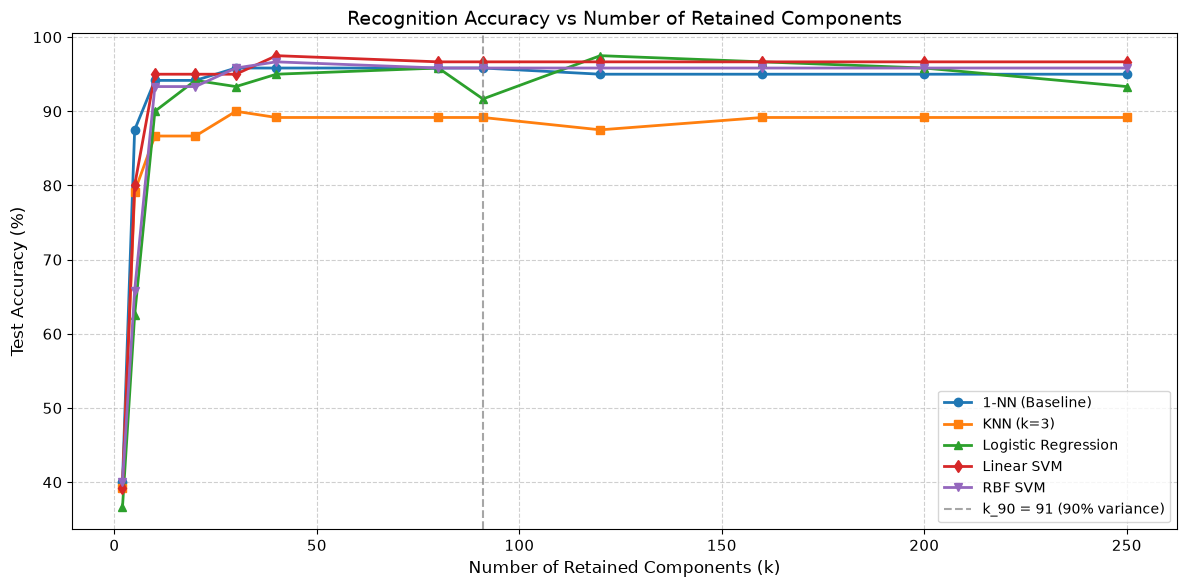

--- Best Accuracy Achieved by Each Model ---
              Model  Optimal k Peak Accuracy (%) Accuracy at k=91 (%)
    1-NN (Baseline)         30            95.83%               95.83%
          KNN (k=3)         30            90.00%               89.17%
Logistic Regression        120            97.50%               91.67%
         Linear SVM         40            97.50%               96.67%
            RBF SVM         40            96.67%               95.83%


In [13]:
k_test_range = [2, 5, 10, 20, 30, 40, k_90, 80, 120, 160, 200, 250]
k_test_range = sorted(list(set(k_test_range)))

acc_curves = {
    "1-NN (Baseline)": [],
    "KNN (k=3)": [],
    "Logistic Regression": [],
    "Linear SVM": [],
    "RBF SVM": []
}

for k in k_test_range:
    Vk = Vt_svd[:k]
    Z_tr = np.dot(X_train_centered, Vk.T)
    Z_te = np.dot(X_test_centered, Vk.T)
    
    # 1-NN Baseline
    p_1nn, _, _ = nearest_neighbor_predict(Z_tr, y_train, Z_te)
    acc_curves["1-NN (Baseline)"].append(accuracy_score(y_test, p_1nn))
    
    # KNN (k=3)
    m_knn = KNeighborsClassifier(n_neighbors=3, metric='euclidean').fit(Z_tr, y_train)
    acc_curves["KNN (k=3)"].append(accuracy_score(y_test, m_knn.predict(Z_te)))
    
    # Logistic Regression
    m_lr = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Z_tr, y_train)
    acc_curves["Logistic Regression"].append(accuracy_score(y_test, m_lr.predict(Z_te)))
    
    # Linear SVM
    m_lin = SVC(kernel='linear', random_state=RANDOM_STATE).fit(Z_tr, y_train)
    acc_curves["Linear SVM"].append(accuracy_score(y_test, m_lin.predict(Z_te)))
    
    # RBF SVM
    m_rbf = SVC(kernel='rbf', random_state=RANDOM_STATE).fit(Z_tr, y_train)
    acc_curves["RBF SVM"].append(accuracy_score(y_test, m_rbf.predict(Z_te)))

# Plot Accuracy vs Number of Components
plt.figure(figsize=(12, 6))
marker_styles = ['o', 's', '^', 'd', 'v']

for (model_name, accs), marker in zip(acc_curves.items(), marker_styles):
    plt.plot(k_test_range, np.array(accs) * 100, marker=marker, linewidth=2, label=model_name)

plt.axvline(x=k_90, color='gray', linestyle='--', alpha=0.7, label=f"k_90 = {k_90} (90% variance)")
plt.xlabel("Number of Retained Components (k)", fontsize=12)
plt.ylabel("Test Accuracy (%)", fontsize=12)
plt.title("Recognition Accuracy vs Number of Retained Components", fontsize=14)
plt.legend(loc='lower right', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Summary table of best performance
peak_summary = []
for model_name, accs in acc_curves.items():
    best_idx = np.argmax(accs)
    best_k = k_test_range[best_idx]
    best_acc = accs[best_idx]
    k90_idx = k_test_range.index(k_90)
    k90_acc = accs[k90_idx]
    peak_summary.append({
        "Model": model_name,
        "Optimal k": best_k,
        "Peak Accuracy (%)": f"{best_acc * 100:.2f}%",
        f"Accuracy at k={k_90} (%)": f"{k90_acc * 100:.2f}%"
    })

print("--- Best Accuracy Achieved by Each Model ---")
print(pd.DataFrame(peak_summary).to_string(index=False))

## Summary and Conclusions

### 1. Representation & Dimensionality Reduction
- Raw face images have **10,304 pixels** each.
- Using PCA written with NumPy linear algebra, **91 components** keep 90% of the total variance.
- That is 91 numbers per face instead of 10,304, about **113 times fewer** (99.12% saving). This does not count the shared mean face and eigenfaces, which are stored once.

### 2. Eigendecomposition vs SVD
- The 280 x 280 eigendecomposition and the direct SVD give the same principal directions (cosine similarity 1.0) and the same eigenvalues.
- In this run the eigendecomposition was faster (0.22 s vs 3.58 s). SVD is the more careful choice numerically, so it is used for the rest of the notebook.

### 3. Face Reconstruction & Compression
- With k = 5 to 15, reconstructions show only a rough outline and lighting.
- With k = 91, the faces are clear and recognizable.
- Beyond k = 150 the images barely improve while more numbers are stored.

### 4. Classification & Recognition
- Closest-face matching reached 95.00% on raw pixels and 95.83% on PCA values. The PCA version was about 135 times faster.
- At k = 91, the linear SVM did best (96.67%). The closest-face method, KNN (k=1) and the RBF SVM all got 95.83%, Logistic Regression got 91.67% and KNN (k=3) got 89.17%.
- Accuracy rises quickly up to about 30 components. Four of the five models peak at 30 to 40 components, so a smaller representation than k = 91 works just as well. Logistic Regression is the exception: it peaked at 120 components (97.50%) and gave convergence warnings, so it may do better with scaled features or more iterations.
- The best results were 97.50% for the linear SVM (40 components) and for Logistic Regression (120 components).
- The test set has only 120 images, so a difference of one or two images between methods is small.